In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter

In [2]:
sns.set_context("paper")
sns.set_style("white")

In [3]:
max_mean_sigma_row, max_var_sigma_row = np.load("data/sigma_max_mean_p.npy"), np.load("data/sigma_max_var_p.npy")

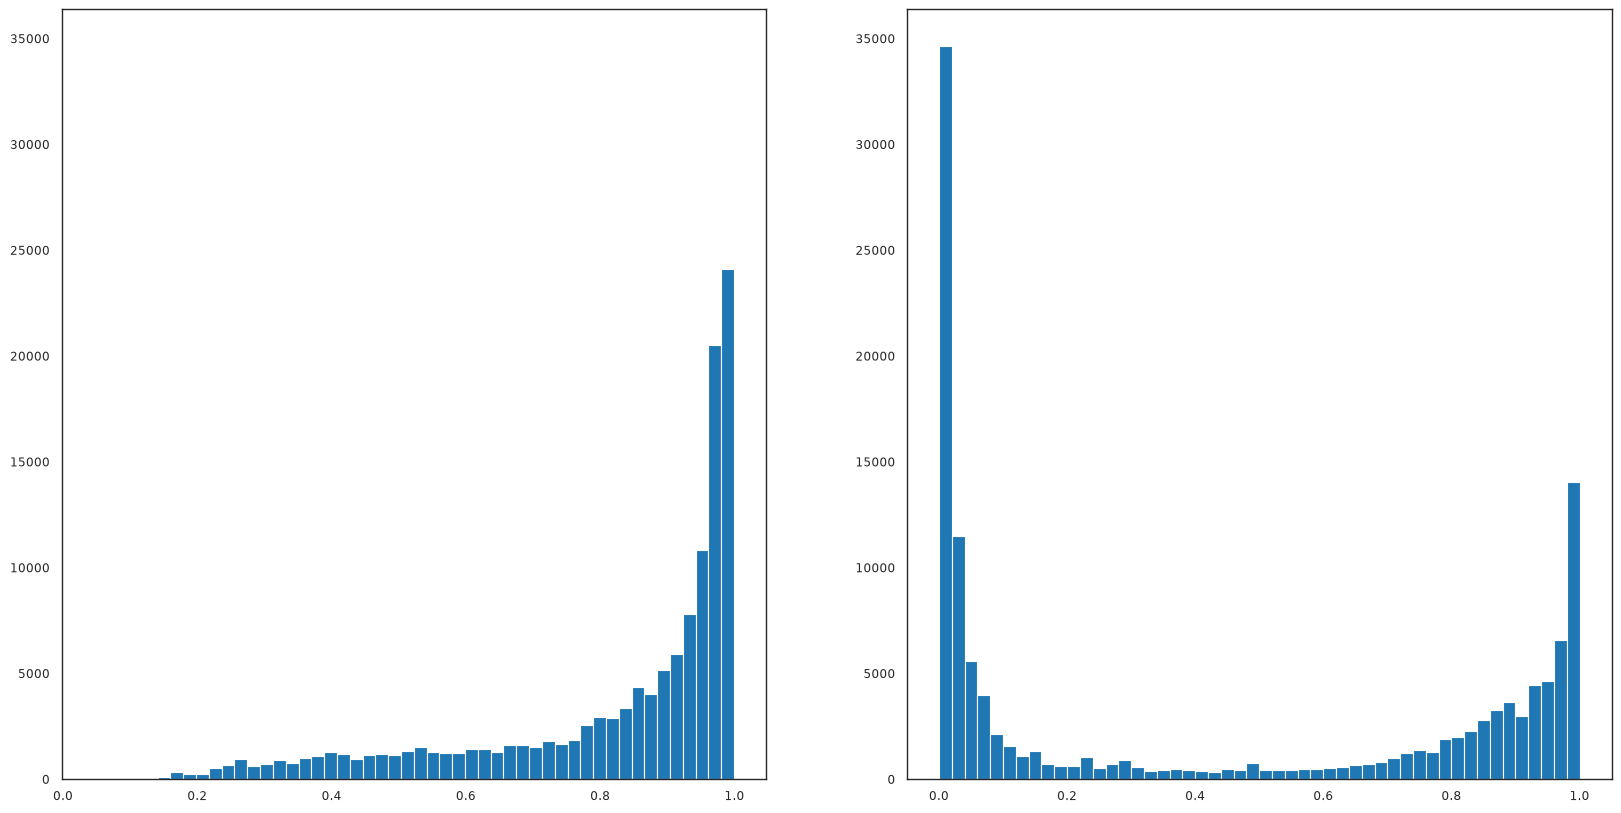

In [4]:
fig = plt.figure(figsize=(20,10))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2, sharey=ax1)

ax1.hist(max_mean_sigma_row, bins=50)
ax2.hist(max_var_sigma_row, bins=50)

plt.show()

In [5]:
max_mean_sigma_row.mean(), 4 * max_mean_sigma_row.var()

(np.float64(0.8197607376784217), np.float64(0.17428842955804819))

In [6]:
max_var_sigma_row.mean(), 4 * max_var_sigma_row.var()

(np.float64(0.4365485267744439), np.float64(0.7045131106813489))

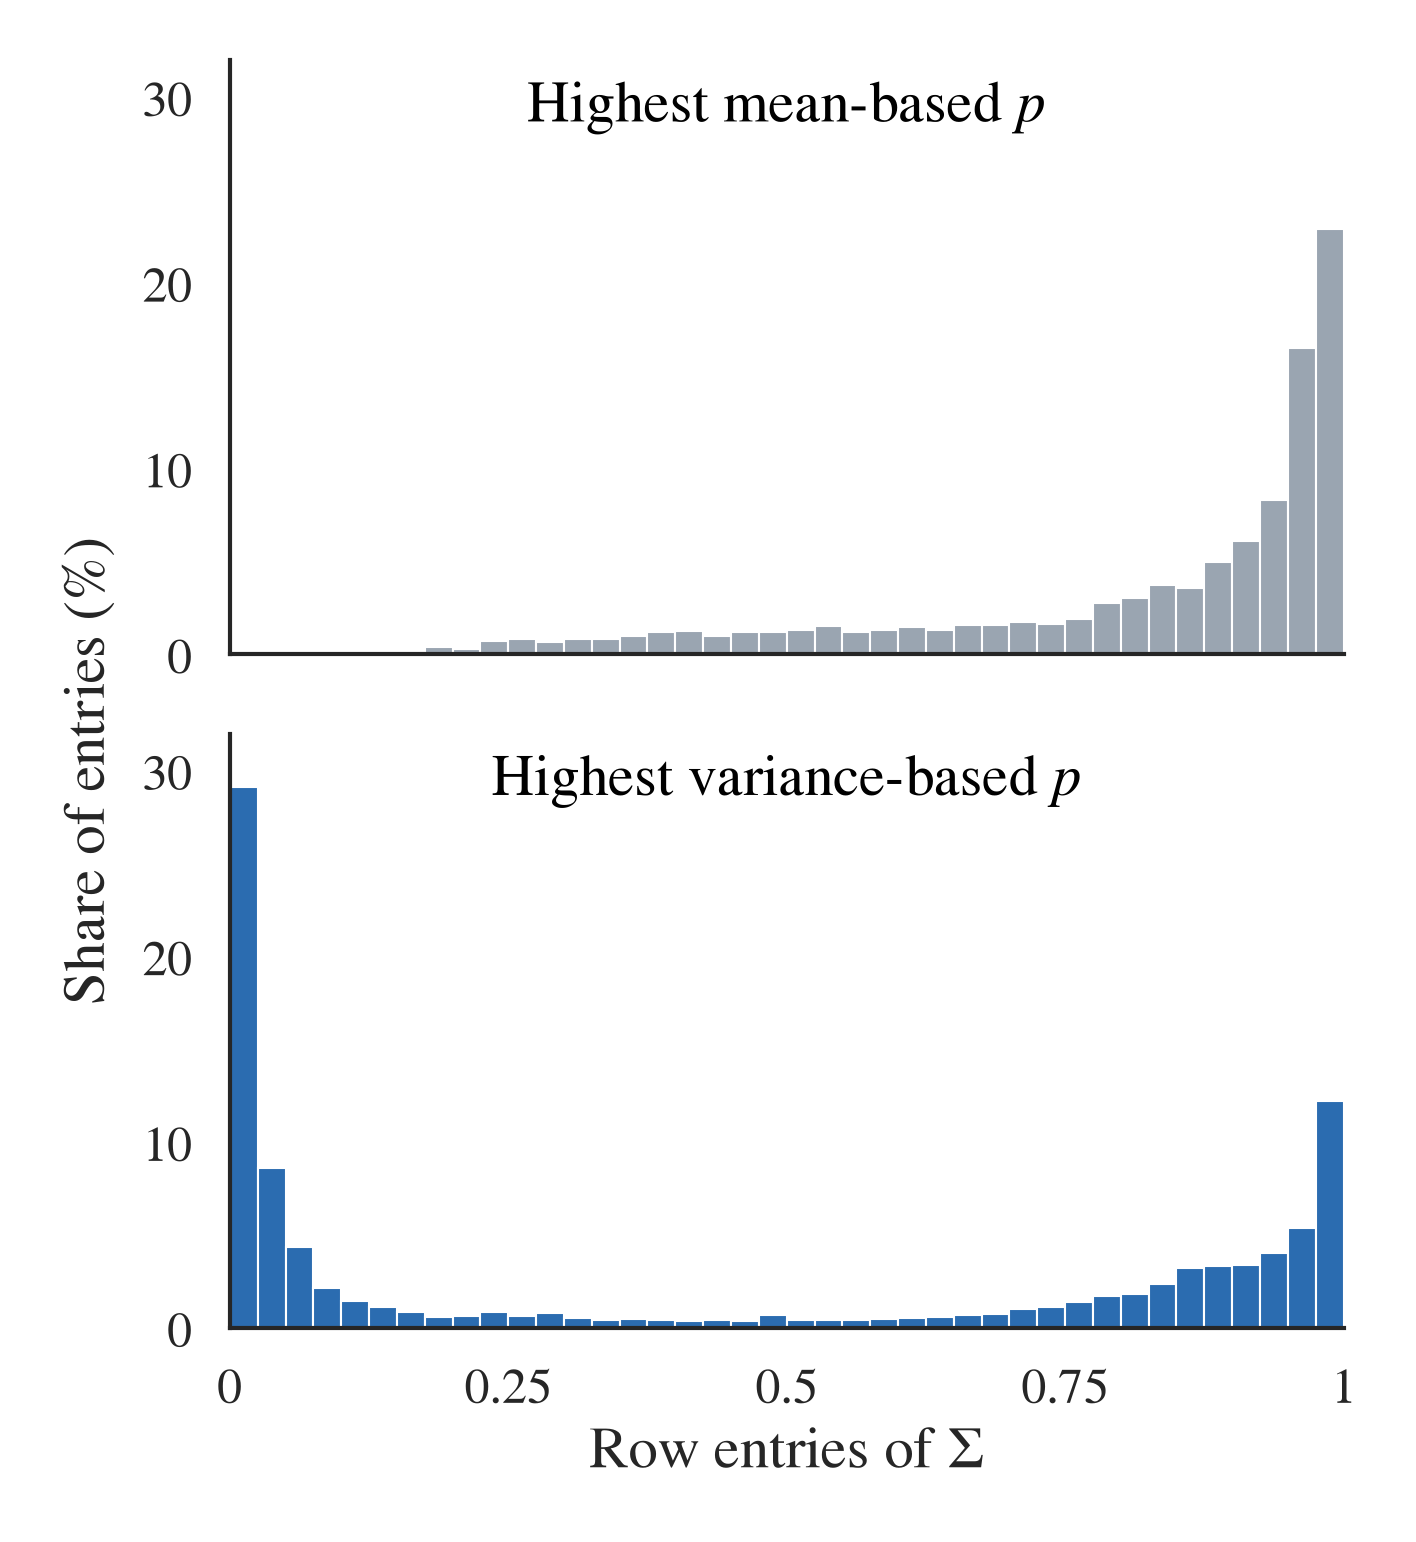

In [10]:
FIG_W, FIG_H = 2.2, 2.45    # inches. 3 x 2.2 in + gaps ~ 6.85 in (Elsevier double-column width)
N_BINS = 40                 # fixed bins on [0, 1] -> identical bin width in both panels
COL_MEAN = "#9AA5B1"        # baseline definition: neutral grey
COL_VAR = "#2B6CB0"         # proposed definition: accent blue
# -----------------------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.major.pad": 2,
    "ytick.major.pad": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


def panel(ax, row, color, title):
    weights = np.full(row.shape, 100.0 / row.size)          # share of recipients, in %
    ax.hist(row, bins=np.linspace(0, 1, N_BINS + 1), weights=weights,
            color=color, edgecolor="white", linewidth=0.25)
    ax.text(0.5, 0.97, title, transform=ax.transAxes, ha="center", va="top",
            fontsize=7, color="black")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_xlim(0, 1)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(FIG_W, FIG_H), sharex=True, sharey=True,
                                   constrained_layout=True, dpi=600)
fig.get_layout_engine().set(h_pad=0.04, w_pad=0.02)

panel(ax1, max_mean_sigma_row, COL_MEAN, "Highest mean-based $p$")
panel(ax2, max_var_sigma_row, COL_VAR, "Highest variance-based $p$")

ax1.set_ylim(0, 32)
ax1.set_yticks([0, 10, 20, 30])
ax2.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax2.set_xlabel(r"Row entries of $\Sigma$", labelpad=1)
fig.supylabel("Share of entries (%)", fontsize=7)

plt.show()

In [12]:
fig.savefig(f"../../../paper/figures/fig_p_sigma_rows.pdf")